# Make a small model tell the truth about itself
A 4-layer char-level GPT trained on Python stdlib source, instrumented six ways:
1. every tensor shape in one training step, with a meaning for each dimension
2. one gradient verified by hand (finite difference vs `backward()`)
3. gradient accumulation broken on purpose (mean of means)
4. grad norm logged every step, one step where it moved before the loss
5. my own MFU, and what's eating the distance to 40%
6. the number 0.1 in fp32, bf16 and fp8 E4M3, bit by bit

Everything below is executed; the outputs you see are the real ones.

In [1]:
import math, json, time, glob, sysconfig, os, subprocess, statistics
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

dev = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("figs", exist_ok=True)
RESULTS = {}
print(torch.__version__, dev, torch.cuda.get_device_name(0) if dev == "cuda" else "")

2.10.0+cu126 cuda NVIDIA GeForce RTX 3060 Laptop GPU


## 0. Data and model
Char-level corpus: the first ~3 MB of top-level `.py` files in the Python stdlib (ASCII only).
Model: pre-LN GPT, learned position embeddings, untied `lm_head`, bias-free linear layers, dropout = 0.

In [2]:
files = sorted(glob.glob(os.path.join(sysconfig.get_paths()["stdlib"], "*.py")))
text = ""
for f in files:
    try: text += open(f, encoding="utf-8").read()
    except Exception: pass
    if len(text) > 3_000_000: break
text = "".join(c for c in text if ord(c) < 128)
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
V = len(chars)
print(f"{len(text):,} chars, vocab V={V}, train {len(train_data):,}, val {len(val_data):,}")

def get_batch(split, B, T, gen=None):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - T - 1, (B,), generator=gen)
    x = torch.stack([d[i:i+T] for i in ix]); y = torch.stack([d[i+1:i+T+1] for i in ix])
    return x.to(dev), y.to(dev)

class Block(nn.Module):
    def __init__(s, C, H):
        super().__init__()
        s.H = H; s.ln1 = nn.LayerNorm(C); s.qkv = nn.Linear(C, 3*C, bias=False); s.proj = nn.Linear(C, C, bias=False)
        s.ln2 = nn.LayerNorm(C); s.fc = nn.Linear(C, 4*C, bias=False); s.out = nn.Linear(4*C, C, bias=False)
    def forward(s, x, tr=None):
        B, T, C = x.shape; H = s.H; D = C // H
        t = tr or (lambda *a: None)
        h = s.ln1(x);                                  t("ln1 out", h, "B,T,C")
        qkv = s.qkv(h);                                t("qkv = Linear(C->3C)", qkv, "B,T,3C")
        q, k, v = qkv.split(C, dim=2)
        q, k, v = [z.view(B, T, H, D).transpose(1, 2) for z in (q, k, v)]
        t("q (per head)", q, "B,H,T,D"); t("k (per head)", k, "B,H,T,D"); t("v (per head)", v, "B,H,T,D")
        a = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        t("attn out (softmax(QK^T/sqrt(D)) V, causal)", a, "B,H,T,D")
        a = a.transpose(1, 2).contiguous().view(B, T, C); t("heads re-merged", a, "B,T,C")
        x = x + s.proj(a);                             t("residual after attn", x, "B,T,C")
        m = s.fc(s.ln2(x));                            t("mlp hidden = Linear(C->4C)", m, "B,T,4C")
        m = F.gelu(m); m = s.out(m);                   t("mlp out = Linear(4C->C)", m, "B,T,C")
        return x + m

class GPT(nn.Module):
    def __init__(s, V, T, C, L, H):
        super().__init__()
        s.T = T; s.C = C; s.L = L
        s.wte = nn.Embedding(V, C); s.wpe = nn.Embedding(T, C)
        s.blocks = nn.ModuleList([Block(C, H) for _ in range(L)])
        s.lnf = nn.LayerNorm(C); s.lm_head = nn.Linear(C, V, bias=False)
        s.apply(s._init)
        for b in s.blocks:                              # GPT-2 style scaled residual init
            nn.init.normal_(b.proj.weight, std=0.02/math.sqrt(2*L)); nn.init.normal_(b.out.weight, std=0.02/math.sqrt(2*L))
    def _init(s, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, std=0.02)
    def forward(s, idx, targets=None, reduction="mean", tr=None):
        B, T = idx.shape
        t = tr or (lambda *a: None)
        t("idx (token ids)", idx, "B,T")
        x = s.wte(idx) + s.wpe(torch.arange(T, device=idx.device))
        t("x = wte(idx)+wpe(pos)", x, "B,T,C")
        for i, b in enumerate(s.blocks):
            x = b(x, tr=tr if i == 0 else None)
        x = s.lnf(x);                                   t("final LN", x, "B,T,C")
        logits = s.lm_head(x);                          t("logits = lm_head(x)", logits, "B,T,V")
        if targets is None: return logits, None
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100, reduction=reduction)
        t("targets", targets, "B,T"); t("loss", loss, "scalar")
        return logits, loss

CFG = dict(V=V, T=128, C=128, L=4, H=4)
def make(seed=0, **over):
    torch.manual_seed(seed); return GPT(**{**CFG, **over}).to(dev)
m = make()
nparam = sum(p.numel() for p in m.parameters())
print(f"params: {nparam:,}")

3,019,718 chars, vocab V=96, train 2,717,746, val 301,972


params: 829,696


## 1. Every tensor shape in one step
Symbols: **B** = batch (independent sequences), **T** = sequence length (token positions, causal),
**C** = d_model (residual stream width), **H** = attention heads, **D** = C/H head dim, **V** = vocab (one logit per character),
**4C** = MLP hidden width.

In [3]:
B, T = 16, 128
C, H, L = CFG["C"], CFG["H"], CFG["L"]
D = C // H
sym = dict(B=B, T=T, C=C, H=H, D=D, V=V)
MEAN = {
 "B": "batch: independent sequences", "T": "token position within a sequence (causal order)",
 "C": "d_model: width of the residual stream", "H": "attention head index",
 "D": "per-head feature dim (C/H)", "V": "vocab: one logit per character", "3C": "q,k,v concatenated", "4C": "MLP hidden width",
 "scalar": "single number"}
def tr(name, x, dims):
    print(f"  {name:<46} {str(tuple(x.shape)):<22} [{dims}]  dtype={str(x.dtype).replace('torch.','')}")

opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
x, y = get_batch("train", B, T)
print("FORWARD (block 0 shown; blocks 1..%d are identical in shape)" % (L-1))
logits, loss = m(x, y, tr=tr)
print("\nDimension meanings:")
for k, v in MEAN.items(): print(f"  {k:<7} {v}" + (f"  = {sym[k]}" if k in sym else ""))
loss.backward()
opt.step()
print("\nPARAMETERS: shape == .grad shape; AdamW keeps exp_avg and exp_avg_sq of the same shape")
pm = {"wte.weight": "[V,C]: row = embedding of one character", "wpe.weight": "[T,C]: row = embedding of one position",
      "ln1.weight": "[C]: LN gain (ln1.bias same)", "qkv.weight": "[3C,C]: out-features (q|k|v stacked), in-features C",
      "proj.weight": "[C,C]: merges heads back to residual", "ln2.weight": "[C]: LN gain", "fc.weight": "[4C,C]: MLP up-projection",
      "out.weight": "[C,4C]: MLP down-projection", "lnf.weight": "[C]", "lm_head.weight": "[V,C]: residual -> char logits"}
for name, p in m.named_parameters():
    key = name.split("blocks.0.")[-1] if "blocks." in name else name
    if "blocks." in name and not name.startswith("blocks.0."): continue
    st = opt.state[p]
    print(f"  {name:<22} param {str(tuple(p.shape)):<12} grad {str(tuple(p.grad.shape)):<12} exp_avg {str(tuple(st['exp_avg'].shape)):<12} -> {pm.get(key, '')}")
print(f"  (x{L} blocks; loss is a 0-d scalar = mean over B*T = {B*T} token CE terms)")

FORWARD (block 0 shown; blocks 1..3 are identical in shape)
  idx (token ids)                                (16, 128)              [B,T]  dtype=int64
  x = wte(idx)+wpe(pos)                          (16, 128, 128)         [B,T,C]  dtype=float32
  ln1 out                                        (16, 128, 128)         [B,T,C]  dtype=float32
  qkv = Linear(C->3C)                            (16, 128, 384)         [B,T,3C]  dtype=float32
  q (per head)                                   (16, 4, 128, 32)       [B,H,T,D]  dtype=float32
  k (per head)                                   (16, 4, 128, 32)       [B,H,T,D]  dtype=float32
  v (per head)                                   (16, 4, 128, 32)       [B,H,T,D]  dtype=float32
  attn out (softmax(QK^T/sqrt(D)) V, causal)     (16, 4, 128, 32)       [B,H,T,D]  dtype=float32
  heads re-merged                                (16, 128, 128)         [B,T,C]  dtype=float32
  residual after attn                            (16, 128, 128)         [B,T,C] 

  mlp hidden = Linear(C->4C)                     (16, 128, 512)         [B,T,4C]  dtype=float32
  mlp out = Linear(4C->C)                        (16, 128, 128)         [B,T,C]  dtype=float32
  final LN                                       (16, 128, 128)         [B,T,C]  dtype=float32
  logits = lm_head(x)                            (16, 128, 96)          [B,T,V]  dtype=float32
  targets                                        (16, 128)              [B,T]  dtype=int64
  loss                                           ()                     [scalar]  dtype=float32

Dimension meanings:
  B       batch: independent sequences  = 16
  T       token position within a sequence (causal order)  = 128
  C       d_model: width of the residual stream  = 128
  H       attention head index  = 4
  D       per-head feature dim (C/H)  = 32
  V       vocab: one logit per character  = 96
  3C      q,k,v concatenated
  4C      MLP hidden width
  scalar  single number



PARAMETERS: shape == .grad shape; AdamW keeps exp_avg and exp_avg_sq of the same shape
  wte.weight             param (96, 128)    grad (96, 128)    exp_avg (96, 128)    -> [V,C]: row = embedding of one character
  wpe.weight             param (128, 128)   grad (128, 128)   exp_avg (128, 128)   -> [T,C]: row = embedding of one position
  blocks.0.ln1.weight    param (128,)       grad (128,)       exp_avg (128,)       -> [C]: LN gain (ln1.bias same)
  blocks.0.ln1.bias      param (128,)       grad (128,)       exp_avg (128,)       -> 
  blocks.0.qkv.weight    param (384, 128)   grad (384, 128)   exp_avg (384, 128)   -> [3C,C]: out-features (q|k|v stacked), in-features C
  blocks.0.proj.weight   param (128, 128)   grad (128, 128)   exp_avg (128, 128)   -> [C,C]: merges heads back to residual
  blocks.0.ln2.weight    param (128,)       grad (128,)       exp_avg (128,)       -> [C]: LN gain
  blocks.0.ln2.bias      param (128,)       grad (128,)       exp_avg (128,)       -> 
  blocks.0.f

## 2. Verify one gradient by hand
Nudge one weight `w` by ±ε, re-measure the loss, and take the central difference
`(L(w+ε) − L(w−ε)) / 2ε`. Compare with `p.grad` from `backward()`.
I do it in **float64 on CPU** (so the check is limited by calculus, not rounding), on a fixed batch,
and then repeat in **float32** to show where it stops agreeing.

In [4]:
def grad_check(dtype, eps, names_idx, seed=0):
    mm = make(seed).to("cpu").to(dtype)
    g = torch.Generator().manual_seed(1)
    d = train_data
    ix = torch.randint(len(d) - 33, (4,), generator=g)
    xx = torch.stack([d[i:i+32] for i in ix]); yy = torch.stack([d[i+1:i+33] for i in ix])
    # make weights non-tiny so every path carries signal
    with torch.no_grad():
        for p in mm.parameters():
            if p.dim() == 2: p.mul_(10)
    mm.zero_grad(); _, l0 = mm(xx, yy); l0.backward()
    rows = []
    for name, idx in names_idx:
        p = dict(mm.named_parameters())[name]
        ana = p.grad[idx].item()
        with torch.no_grad():
            old = p[idx].item()
            p[idx] = old + eps; lp = mm(xx, yy)[1].item()
            p[idx] = old - eps; lm = mm(xx, yy)[1].item()
            p[idx] = old
        num = (lp - lm) / (2 * eps)
        rows.append((name, tuple(idx), ana, num, abs(ana-num)/max(abs(ana), abs(num), 1e-30)))
    return l0.item(), rows

targets = [("blocks.0.qkv.weight", (5, 7)), ("blocks.2.fc.weight", (100, 3)), ("blocks.3.out.weight", (9, 100)),
           ("lm_head.weight", (stoi['e'], 11)), ("wte.weight", (stoi['e'], 4))]
for dt, eps in [(torch.float64, 1e-6), (torch.float32, 1e-2), (torch.float32, 1e-4)]:
    l0, rows = grad_check(dt, eps, targets)
    print(f"\n{str(dt):<14} eps={eps:g}   loss={l0:.6f}")
    print(f"  {'param[idx]':<34}{'backward()':>14}{'finite diff':>14}{'rel err':>11}")
    for name, idx, a, nmr, r in rows:
        print(f"  {name+str(list(idx)):<34}{a:>14.8f}{nmr:>14.8f}{r:>11.2e}")
    RESULTS[f"gradcheck_{str(dt)[6:]}_eps{eps:g}"] = [dict(param=f"{n}{list(i)}", backward=a, fd=nm, rel=r) for n, i, a, nm, r in rows]


torch.float64  eps=1e-06   loss=6.446688
  param[idx]                            backward()   finite diff    rel err
  blocks.0.qkv.weight[5, 7]            -0.00383845   -0.00383845   7.26e-08
  blocks.2.fc.weight[100, 3]            0.00648477    0.00648477   3.69e-08
  blocks.3.out.weight[9, 100]           0.07616242    0.07616242   5.18e-09
  lm_head.weight[70, 11]                0.06141812    0.06141812   6.38e-09
  wte.weight[70, 4]                    -0.02306645   -0.02306645   2.87e-08



torch.float32  eps=0.01   loss=6.446688
  param[idx]                            backward()   finite diff    rel err
  blocks.0.qkv.weight[5, 7]            -0.00383829   -0.00381470   6.15e-03
  blocks.2.fc.weight[100, 3]            0.00648476    0.00648499   3.45e-05
  blocks.3.out.weight[9, 100]           0.07616240    0.07617474   1.62e-04
  lm_head.weight[70, 11]                0.06141813    0.06141663   2.45e-05
  wte.weight[70, 4]                    -0.02306691   -0.02303123   1.55e-03



torch.float32  eps=0.0001   loss=6.446688
  param[idx]                            backward()   finite diff    rel err
  blocks.0.qkv.weight[5, 7]            -0.00383829   -0.00715256   4.63e-01
  blocks.2.fc.weight[100, 3]            0.00648476    0.00476837   2.65e-01
  blocks.3.out.weight[9, 100]           0.07616240    0.07390976   2.96e-02
  lm_head.weight[70, 11]                0.06141813    0.06198883   9.21e-03
  wte.weight[70, 4]                    -0.02306691   -0.02384186   3.25e-02


**Reading it.** See the printed table: float64 vs float32 relative errors, and what happens when ε shrinks in float32.
The loss is stored to ~7 digits in fp32, so `L(w+ε)−L(w−ε)` is a difference of two nearly equal numbers and rounding noise / (2ε) grows as ε shrinks.
`backward()` is the trustworthy number; the naive fp32 finite difference is the unreliable instrument.

## 3. Break gradient accumulation on purpose
One optimizer step = 4 micro-batches of 8 sequences, but each micro-batch has a **different sequence length** (drawn from {8,16,32,64,128}),
so token counts differ by up to 16×.

* **Right:** `loss = Σ_tokens CE / total_tokens_in_step`, accumulated per micro-batch (every token weighs the same).
* **Wrong:** `loss = mean_k( mean_tokens_in_micro_k CE )` — the average of averages. A token in micro-batch *k* weighs `1/(4·n_k)`, so tokens in an 8-long micro-batch count 16× more than those in a 128-long one.

First a sanity check that "right" is truly right: it must equal one big padded batch with `ignore_index`.

In [5]:
LENS = [8, 16, 32, 64, 128]; NMICRO = 4; MB = 8
def step_batches(gen, lens=LENS):
    ls = [lens[i] for i in torch.randint(len(lens), (NMICRO,), generator=gen)]
    return [get_batch("train", MB, l, gen) for l in ls]

def accum_grads(model, mbs, mode):
    model.zero_grad()
    tot = sum(y.numel() for _, y in mbs); per = []
    for x, y in mbs:
        _, ls = model(x, y, reduction="sum"); n_k = y.numel()
        per.append(ls.item() / n_k)
        if mode == "right": (ls / tot).backward()
        else:               (ls / n_k / len(mbs)).backward()
    true_tok_mean = sum(p * y.numel() for p, (_, y) in zip(per, mbs)) / tot
    return true_tok_mean, sum(per) / len(per)          # (token-weighted loss, mean-of-means loss)

g = torch.Generator().manual_seed(7)
mbs = step_batches(g)
print("micro-batch lengths:", [x.shape[1] for x, _ in mbs])
mm = make(0)
tl, mom = accum_grads(mm, mbs, "right"); g_right = torch.cat([p.grad.flatten() for p in mm.parameters()]).clone()
Tm = max(x.shape[1] for x, _ in mbs)
X = torch.zeros(len(mbs)*MB, Tm, dtype=torch.long, device=dev); Y = torch.full_like(X, -100)
for k, (x, y) in enumerate(mbs): X[k*MB:(k+1)*MB, :x.shape[1]] = x; Y[k*MB:(k+1)*MB, :y.shape[1]] = y
mm.zero_grad(); _, lbig = mm(X, Y); lbig.backward()
g_pad = torch.cat([p.grad.flatten() for p in mm.parameters()])
print(f"token-weighted loss {tl:.6f} | padded single batch {lbig.item():.6f} | max|grad diff| {(g_right-g_pad).abs().max():.2e}")
tl, mom = accum_grads(mm, mbs, "wrong"); g_wrong = torch.cat([p.grad.flatten() for p in mm.parameters()])
cos = F.cosine_similarity(g_right, g_wrong, dim=0).item()
print(f"mean-of-means loss {mom:.6f} vs true {tl:.6f}  | grad cosine(right,wrong)={cos:.4f}  |g_wrong|/|g_right|={g_wrong.norm()/g_right.norm():.3f}")
RESULTS["accum_one_step"] = dict(lens=[x.shape[1] for x, _ in mbs], true_loss=tl, mean_of_means=mom, grad_cos=cos,
                                 norm_ratio=(g_wrong.norm()/g_right.norm()).item(), padded_vs_right_max_diff=(g_right-g_pad).abs().max().item())

micro-batch lengths: [8, 32, 16, 16]


token-weighted loss 4.538249 | padded single batch 4.538249 | max|grad diff| 8.94e-08
mean-of-means loss 4.539780 vs true 4.538249  | grad cosine(right,wrong)=0.9932  |g_wrong|/|g_right|=1.003


Now train two identical models (same init, same data stream, same AdamW) that differ **only** in the normalisation, and evaluate both on the same held-out full-length batches.

[mild imbalance: lengths in {8,16,32,64,128}]  (69s)
   final val loss: right=2.5644  wrong=2.5689  (wrong - right = +0.0046)
   val loss averaged over last 5 evals: right=2.5950 wrong=2.5969
   mean |reported - true token loss| in the wrong run: 0.0709 nats (max 0.336)


[extreme imbalance: lengths in {2,128}]  (65s)
   final val loss: right=2.5709  wrong=2.6333  (wrong - right = +0.0625)
   val loss averaged over last 5 evals: right=2.5938 wrong=2.6602
   mean |reported - true token loss| in the wrong run: 0.1341 nats (max 0.610)


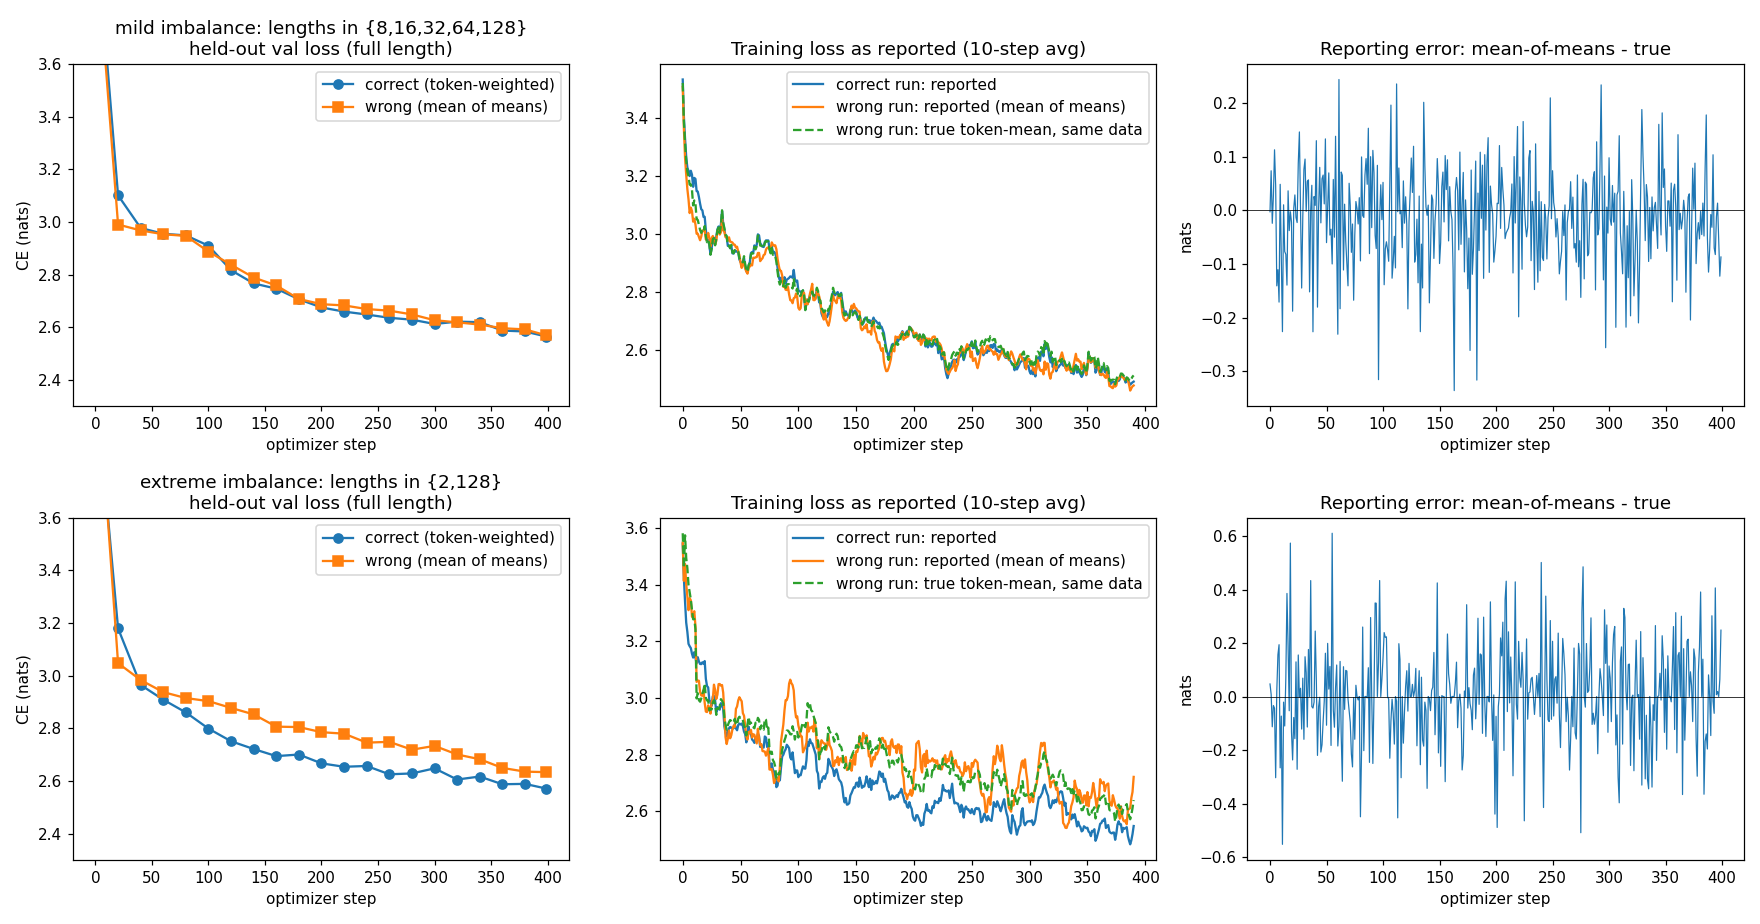

In [6]:
@torch.no_grad()
def evaluate(model, n=30):
    g = torch.Generator().manual_seed(123); tot = 0
    for _ in range(n):
        x, y = get_batch("val", 16, 128, g); tot += model(x, y)[1].item()
    return tot / n

STEPS = 400
def run_accum(mode, lens):
    model = make(0); o = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.0)
    g = torch.Generator().manual_seed(42); rep, true, val, vs = [], [], [], []
    for s in range(STEPS):
        mbs = step_batches(g, lens)
        tl, mom = accum_grads(model, mbs, mode); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); o.step()
        rep.append(tl if mode == "right" else mom); true.append(tl)
        if s % 20 == 0 or s == STEPS-1: val.append(evaluate(model)); vs.append(s)
    return dict(reported=rep, true=true, val=val, vs=vs)

def sm(a, k=10): a = np.array(a); return np.convolve(a, np.ones(k)/k, mode="valid")
SCEN = [("mild imbalance: lengths in {8,16,32,64,128}", LENS), ("extreme imbalance: lengths in {2,128}", [2, 128])]
fig, axs = plt.subplots(len(SCEN), 3, figsize=(16, 4.2*len(SCEN)))
RESULTS["accum_train"] = {}
for row, (title, lens) in zip(axs, SCEN):
    t0 = time.time(); R = run_accum("right", lens); W = run_accum("wrong", lens)
    gap = np.abs(np.array(W['reported'])-np.array(W['true']))
    print(f"[{title}]  ({time.time()-t0:.0f}s)")
    print(f"   final val loss: right={R['val'][-1]:.4f}  wrong={W['val'][-1]:.4f}  (wrong - right = {W['val'][-1]-R['val'][-1]:+.4f})")
    print(f"   val loss averaged over last 5 evals: right={np.mean(R['val'][-5:]):.4f} wrong={np.mean(W['val'][-5:]):.4f}")
    print(f"   mean |reported - true token loss| in the wrong run: {gap.mean():.4f} nats (max {gap.max():.3f})")
    RESULTS["accum_train"][title] = dict(final_val_right=R['val'][-1], final_val_wrong=W['val'][-1],
        last5_right=float(np.mean(R['val'][-5:])), last5_wrong=float(np.mean(W['val'][-5:])), mean_abs_report_gap=float(gap.mean()), max_abs_report_gap=float(gap.max()))
    row[0].plot(R['vs'], R['val'], "o-", label="correct (token-weighted)"); row[0].plot(W['vs'], W['val'], "s-", label="wrong (mean of means)")
    row[0].set(title=f"{title}\nheld-out val loss (full length)", xlabel="optimizer step", ylabel="CE (nats)"); row[0].legend(); row[0].set_ylim(2.3, 3.6)
    row[1].plot(sm(R['reported']), label="correct run: reported"); row[1].plot(sm(W['reported']), label="wrong run: reported (mean of means)")
    row[1].plot(sm(W['true']), "--", label="wrong run: true token-mean, same data")
    row[1].set(title="Training loss as reported (10-step avg)", xlabel="optimizer step"); row[1].legend()
    row[2].plot(np.array(W['reported'])-np.array(W['true']), lw=.8); row[2].axhline(0, c="k", lw=.5)
    row[2].set(title="Reporting error: mean-of-means - true", xlabel="optimizer step", ylabel="nats")
plt.tight_layout(); plt.savefig("figs/accumulation.png", dpi=110); plt.close(); display(Image("figs/accumulation.png"))

## 4. Grad norm every step — and a step where it moved before the loss
Per step I log: the **train-batch loss**, the **pre-clip grad norm**, and the loss on one **fixed held-out batch** (32x128 tokens, evaluated *before* the step's update).
The fixed batch matters: train-batch loss is dominated by which batch you drew (+-0.15 nats), so it can't show the small effect of one update.

"Grad norm moved before the loss" = at step *t* the grad norm jumps (> 2x its trailing-20 median) while the fixed-batch loss at *t* hasn't moved, and the loss is higher at *t+1*.
That is only a correlation, so I test it with a **counterfactual**: snapshot model + optimizer + data-RNG at step *t*, then branch (a) apply the update, (b) skip it. Same batches afterwards. If (a) is worse than (b) at t+1.. the big gradient really did it.

Two runs: **A**, a healthy run (AdamW lr 3e-3), and **B**, the same model with the LR ramped linearly 3e-3 -> 0.1 between steps 100 and 400 to push it toward instability.

In [7]:
import copy
XV, YV = get_batch("val", 32, 128, torch.Generator().manual_seed(99))

def one_step(model, o, g, B, T, clip, update=True):
    x, y = get_batch("train", B, T, g)
    _, l = model(x, y); o.zero_grad(); l.backward()
    gn = torch.nn.utils.clip_grad_norm_(model.parameters(), clip).item()
    if update: o.step()
    return l.item(), gn

@torch.no_grad()
def fixed_loss(model): return model(XV, YV)[1].item()

def run_logged(lr_fn, steps, snap_at=(), seed=0, B=16, T=128, clip=1.0):
    model = make(seed); o = torch.optim.AdamW(model.parameters(), lr=lr_fn(0), weight_decay=0.0)
    g = torch.Generator().manual_seed(5); L, G, FL, snaps = [], [], [], {}
    for s in range(steps):
        for pg in o.param_groups: pg["lr"] = lr_fn(s)
        FL.append(fixed_loss(model))
        if s in snap_at: snaps[s] = (copy.deepcopy(model.state_dict()), copy.deepcopy(o.state_dict()), g.get_state())
        l, gn = one_step(model, o, g, B, T, clip); L.append(l); G.append(gn)
    return np.array(L), np.array(G), np.array(FL), snaps

def branch(snap, t, lr_fn, update, k=8, B=16, T=128, clip=1.0):
    model = make(0); model.load_state_dict(snap[0]); o = torch.optim.AdamW(model.parameters(), lr=lr_fn(t), weight_decay=0.0); o.load_state_dict(copy.deepcopy(snap[1]))
    g = torch.Generator(); g.set_state(snap[2]); out = []
    for s in range(t, t+k):
        for pg in o.param_groups: pg["lr"] = lr_fn(s)
        one_step(model, o, g, B, T, clip, update=(update or s != t)); out.append(fixed_loss(model))   # fixed loss at s+1
    return np.array(out)

def candidates(G, FL, start=30, w=20, ratio=2.0, tol=0.03, top=4):
    c = [t for t in range(start, len(G)-10) if G[t] > ratio*np.median(G[t-w:t]) and abs(FL[t]-np.median(FL[t-5:t])) < tol]
    return sorted(c, key=lambda t: -G[t])[:top]

def analyse(name, lr_fn, steps, start):
    L, G, FL, _ = run_logged(lr_fn, steps)
    cs = candidates(G, FL, start)
    _, _, _, snaps = run_logged(lr_fn, max(cs)+1 if cs else 1, snap_at=cs)
    rows = []
    print(f"{name}: final train loss {L[-1]:.3f}; candidate steps (gnorm > 2x trailing median, fixed loss flat at t): {cs}")
    print(f"  {'t':>4}{'gnorm_t':>9}{'x median':>9}{'fixed@t':>9}{'fixed@t+1 (update)':>20}{'fixed@t+1 (skip)':>18}{'damage@t+1':>12}{'damage@t+4':>12}")
    for t in cs:
        a = branch(snaps[t], t, lr_fn, True); b = branch(snaps[t], t, lr_fn, False)
        rows.append(dict(t=t, gn=float(G[t]), ratio=float(G[t]/np.median(G[t-20:t])), fl_t=float(FL[t]), upd=a.tolist(), skip=b.tolist(), d1=float(a[0]-b[0]), d4=float(a[3]-b[3])))
        print(f"  {t:>4}{G[t]:>9.3f}{G[t]/np.median(G[t-20:t]):>9.2f}{FL[t]:>9.4f}{a[0]:>20.4f}{b[0]:>18.4f}{a[0]-b[0]:>+12.4f}{a[3]-b[3]:>+12.4f}")
    return L, G, FL, rows

lrA = lambda s: 3e-3
lrB = lambda s: 3e-3 + (0.1-3e-3)*min(1, max(0, (s-100)/300))
t0 = time.time()
LA, GA, FLA, rowsA = analyse("Run A (healthy, lr 3e-3)", lrA, 600, 30)
print()
LB, GB, FLB, rowsB = analyse("Run B (lr ramp to 0.1)", lrB, 400, 120)
print(f"({time.time()-t0:.0f}s)")
RESULTS["gradnorm_A"] = rowsA; RESULTS["gradnorm_B"] = rowsB

Run A (healthy, lr 3e-3): final train loss 2.323; candidate steps (gnorm > 2x trailing median, fixed loss flat at t): [531, 261, 474, 381]
     t  gnorm_t x median  fixed@t  fixed@t+1 (update)  fixed@t+1 (skip)  damage@t+1  damage@t+4


   531    1.668     4.08   2.4427              2.4563            2.4456     +0.0107     -0.0081


   261    1.166     2.45   2.5961              2.5909            2.5902     +0.0007     +0.0010


   474    1.144     2.53   2.4681              2.4858            2.4933     -0.0075     -0.0022


   381    1.115     2.27   2.5291              2.5770            2.5619     +0.0151     +0.0041



Run B (lr ramp to 0.1): final train loss 2.899; candidate steps (gnorm > 2x trailing median, fixed loss flat at t): [269, 320, 299, 322]
     t  gnorm_t x median  fixed@t  fixed@t+1 (update)  fixed@t+1 (skip)  damage@t+1  damage@t+4


   269    3.092     8.96   2.9120              2.9836            2.9120     +0.0716     +0.0193


   320    2.320     5.73   3.0253              3.0231            3.0253     -0.0022     -0.0004


   299    1.716     4.22   3.0780              3.0589            3.0780     -0.0190     -0.0108


   322    1.331     3.29   3.0197              3.0205            3.0197     +0.0008     +0.0005
(49s)


Chosen (run B): step 269.   (printing around it)
 step  train loss  fixed loss  grad norm
  257      2.8228      2.8714     0.3115
  258      2.8233      2.8805     0.3727
  259      2.6831      2.8807     0.2897
  260      2.9105      2.8793     0.3357
  261      3.0029      2.8639     0.4960
  262      2.8149      2.8904     0.4213
  263      2.8649      2.8916     0.3632
  264      3.0825      2.8882     0.7327
  265      2.8605      2.8953     0.1987
  266      3.0005      2.8942     0.2140
  267      2.7644      2.9013     0.3396
  268      2.8028      2.8958     0.7558
  269      2.8269      2.9120     3.0918   <-- grad norm jumps; fixed loss has not moved yet
  270      2.8345      2.9836     0.7601
  271      2.8779      2.9218     0.2741
  272      2.9384      2.9601     0.4424
  273      2.9364      2.9365     0.8503
  274      2.8474      2.9700     0.2826
  275      3.0573      3.0265     0.4276
  276      2.8812      2.9950     0.2874
  277      2.8824      2.9644     0.53

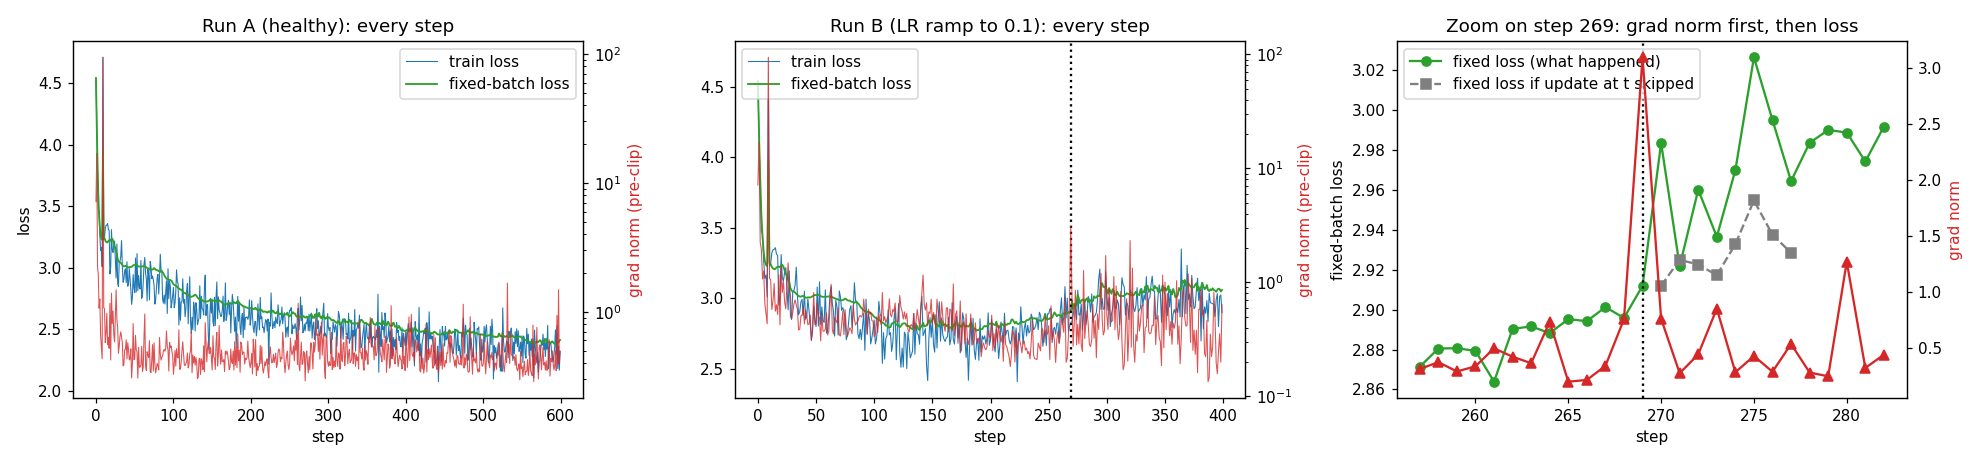

In [8]:
best = max(rowsB, key=lambda r: r["d1"]) if rowsB else None
if best:
    t = best["t"]; lo, hi = t-12, t+14
    print(f"Chosen (run B): step {t}.   (printing around it)")
    print(f"{'step':>5}{'train loss':>12}{'fixed loss':>12}{'grad norm':>11}")
    for s in range(lo, hi): print(f"{s:>5}{LB[s]:>12.4f}{FLB[s]:>12.4f}{GB[s]:>11.4f}" + ("   <-- grad norm jumps; fixed loss has not moved yet" if s == t else ""))
    RESULTS["gradnorm_lead"] = dict(step=int(t), gnorm=best["gn"], ratio=best["ratio"], damage_t1=best["d1"], damage_t4=best["d4"])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].plot(LA, c="C0", lw=.7, label="train loss"); ax[0].plot(FLA, c="C2", lw=1.2, label="fixed-batch loss"); ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].legend(loc="upper right")
a2 = ax[0].twinx(); a2.plot(GA, c="C3", lw=.7, alpha=.8); a2.set_ylabel("grad norm (pre-clip)", color="C3"); a2.set_yscale("log"); ax[0].set_title("Run A (healthy): every step")
ax[1].plot(LB, c="C0", lw=.7, label="train loss"); ax[1].plot(FLB, c="C2", lw=1.2, label="fixed-batch loss"); ax[1].set_xlabel("step"); ax[1].legend(loc="upper left")
a3 = ax[1].twinx(); a3.plot(GB, c="C3", lw=.7, alpha=.8); a3.set_ylabel("grad norm (pre-clip)", color="C3"); a3.set_yscale("log"); ax[1].set_title("Run B (LR ramp to 0.1): every step")
if best:
    ax[1].axvline(t, c="k", ls=":")
    r = np.arange(lo, hi); ax[2].plot(r, FLB[lo:hi], "o-", c="C2", label="fixed loss (what happened)")
    ks = np.arange(t+1, t+1+len(best["skip"]))
    ax[2].plot(ks, best["skip"], "s--", c="C7", label="fixed loss if update at t skipped"); ax[2].set_ylabel("fixed-batch loss"); ax[2].legend(loc="upper left")
    a4 = ax[2].twinx(); a4.plot(r, GB[lo:hi], "^-", c="C3"); a4.set_ylabel("grad norm", color="C3"); ax[2].axvline(t, c="k", ls=":")
    ax[2].set_title(f"Zoom on step {t}: grad norm first, then loss"); ax[2].set_xlabel("step")
plt.tight_layout(); plt.savefig("figs/gradnorm.png", dpi=110); plt.close(); display(Image("figs/gradnorm.png"))

## 5. MFU, computed myself
`MFU = achieved_FLOPs/s ÷ peak_FLOPs/s`. Achieved = tokens/s × FLOPs/token, with
`FLOPs/token = 6·N_matmul + 12·L·C·T`  (6 = 2 fwd + 4 bwd per weight in a matmul; second term = attention QKᵀ and AV, fwd+bwd, causal mask *not* discounted — the PaLM/nanoGPT convention).
`N_matmul` counts weights that sit in matmuls (qkv, proj, fc, out, lm_head); embedding lookups and LN are not matmul FLOPs.

Peak for this GPU (RTX 3060 Laptop, GA106, 30 SMs): GeForce Ampere does bf16 tensor-core MMA with fp32 accumulate at **512 FLOP/clk/SM** (dense)
— half the A100's 1024 — so `peak = 30 × 512 × f_max`. I also measure a big bf16 matmul to see what the chip really sustains.

In [9]:
smi = subprocess.run(["nvidia-smi", "--query-gpu=clocks.max.sm,clocks.sm,power.limit,name", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout.strip().split(", ")
fmax = float(smi[0]); sm_count = torch.cuda.get_device_properties(0).multi_processor_count
PEAK = sm_count * 512 * fmax * 1e6
print(f"nvidia-smi: max SM clock {fmax:.0f} MHz, power limit {smi[2]} W, {sm_count} SMs  ->  theoretical bf16 dense peak = {PEAK/1e12:.1f} TFLOP/s")

def sync(): torch.cuda.synchronize()
a = torch.randn(4096, 4096, device=dev, dtype=torch.bfloat16); b = torch.randn(4096, 4096, device=dev, dtype=torch.bfloat16)
for _ in range(10): a @ b
sync(); t0 = time.time(); N = 50
for _ in range(N): a @ b
sync(); mm_tf = 2*4096**3*N/(time.time()-t0)
print(f"measured 4096^3 bf16 matmul: {mm_tf/1e12:.1f} TFLOP/s  = {100*mm_tf/PEAK:.0f}% of theoretical peak (the ceiling any model can hope for here)")
del a, b

def flops_per_token(model, T):
    nm = sum(p.numel() for n_, p in model.named_parameters() if p.dim() == 2 and "wte" not in n_ and "wpe" not in n_)
    return 6*nm + 12*model.L*model.C*T, nm

def bench(cfg, B, T, steps=30, amp=True):
    model = GPT(**{**CFG, **cfg, "T": T}).to(dev); o = torch.optim.AdamW(model.parameters(), lr=1e-3)
    x, y = get_batch("train", B, T)
    def step():
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=amp): _, l = model(x, y)
        o.zero_grad(set_to_none=True); l.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); o.step()
    for _ in range(5): step()
    sync(); t0 = time.time()
    for _ in range(steps): step()
    sync(); dt = (time.time()-t0)/steps
    fpt, nm = flops_per_token(model, T); tps = B*T/dt
    return dict(cfg=cfg, B=B, T=T, ms_per_step=dt*1e3, tok_s=tps, tflops=tps*fpt/1e12, mfu=tps*fpt/PEAK, n_matmul=nm, mem_gb=torch.cuda.max_memory_allocated()/1e9)

bench_rows = [("lab model (C=128,L=4) B=16,T=128, bf16 autocast", bench({}, 16, 128)),
              ("lab model, fp32 (no autocast)", bench({}, 16, 128, amp=False)),
              ("lab model, bigger batch B=128", bench({}, 128, 128)),
              ("medium (C=512,L=8,H=8) B=16,T=256, bf16", bench(dict(C=512, L=8, H=8), 16, 256)),
              ("medium, B=32,T=256, bf16", bench(dict(C=512, L=8, H=8), 32, 256))]
print(f"\n{'config':<52}{'ms/step':>9}{'tok/s':>11}{'TFLOP/s':>9}{'MFU':>8}")
for name, r in bench_rows: print(f"{name:<52}{r['ms_per_step']:>9.1f}{r['tok_s']:>11,.0f}{r['tflops']:>9.2f}{100*r['mfu']:>7.1f}%")
RESULTS["mfu"] = dict(peak_tflops=PEAK/1e12, matmul_tflops=mm_tf/1e12, rows=[dict(name=n_, **{k: v for k, v in r.items() if k != "cfg"}) for n_, r in bench_rows])

nvidia-smi: max SM clock 2100 MHz, power limit [N/A] W, 30 SMs  ->  theoretical bf16 dense peak = 32.3 TFLOP/s


measured 4096^3 bf16 matmul: 20.9 TFLOP/s  = 65% of theoretical peak (the ceiling any model can hope for here)



config                                                ms/step      tok/s  TFLOP/s     MFU
lab model (C=128,L=4) B=16,T=128, bf16 autocast          30.9     66,337     0.37    1.1%
lab model, fp32 (no autocast)                            17.1    119,729     0.67    2.1%
lab model, bigger batch B=128                            19.2    854,747     4.77   14.8%
medium (C=512,L=8,H=8) B=16,T=256, bf16                  50.6     80,894    13.26   41.1%
medium, B=32,T=256, bf16                                 89.3     91,733    15.03   46.6%


## 6. The number 0.1, by hand, in three formats
0.1 = 1.6 × 2⁻⁴ (since 2⁻⁴ = 0.0625 and 0.1/0.0625 = 1.6). All three formats store `sign | exponent | mantissa` of `(−1)^s · 1.m · 2^(e−bias)`; they differ in how many bits each field gets.

| format | sign | exp bits (bias) | mantissa bits |
|---|---|---|---|
| fp32 | 1 | 8 (127) | 23 |
| bf16 | 1 | 8 (127) | 7 |
| fp8 E4M3 | 1 | 4 (7) | 3 |

**Mantissa of 1.6** = 0.6 in binary: 0.6×2=1.2→**1**, 0.2×2=0.4→**0**, 0.4×2=0.8→**0**, 0.8×2=1.6→**1**, 0.6×2=1.2→**1**, then it repeats: `.1001 1001 1001 …` forever. 0.1 is not representable in any binary format.

* **fp32**: exponent −4 + 127 = 123 = `01111011`. The 23 mantissa bits are `10011001100110011001100`; the next bits are `1 1001…` (more than half an ulp), so **round up** → `10011001100110011001101`.
  `0 | 01111011 | 10011001100110011001101` = `0x3DCCCCCD` = 0.100000001490116…
* **bf16**: same exponent `01111011`, mantissa 7 bits: `1001100` followed by `1 1001…` (> half) → round up → `1001101`.
  `0 | 01111011 | 1001101` = `0x3DCD` = 1.1001101₂ × 2⁻⁴ = 1.6015625/16 = 0.10009765625
* **fp8 E4M3**: exponent −4 + 7 = 3 = `0011`. Mantissa 3 bits: `100` followed by `1 1001…` (> half) → round up → `101`.
  `0 | 0011 | 101` = `0x1D` = 1.101₂ × 2⁻⁴ = 1.625/16 = 0.1015625

The cell below redoes this with code and checks it against PyTorch's own casts.

In [10]:
import struct
def bits_of(val, ebits, mbits, bias):
    """round-to-nearest-even encoder for normal numbers, written from the definition above"""
    s = 0 if val >= 0 else 1; v = abs(val); e = math.floor(math.log2(v)); frac = v / 2**e - 1      # v = 1.frac * 2^e
    mant = round(frac * 2**mbits)                                                                 # Python round = ties-to-even
    if mant == 2**mbits: mant = 0; e += 1
    E = e + bias
    value = (-1)**s * (1 + mant/2**mbits) * 2**(E-bias)
    return s, E, mant, value
for name, eb, mb, bias, tdt in [("fp32", 8, 23, 127, torch.float32), ("bf16", 8, 7, 127, torch.bfloat16), ("fp8 E4M3", 4, 3, 7, torch.float8_e4m3fn)]:
    s, E, mant, value = bits_of(0.1, eb, mb, bias)
    tv = torch.tensor(0.1).to(tdt).float().item()
    raw = {"fp32": lambda: struct.unpack(">I", struct.pack(">f", 0.1))[0],
           "bf16": lambda: torch.tensor(0.1).to(torch.bfloat16).view(torch.int16).item() & 0xFFFF,
           "fp8 E4M3": lambda: torch.tensor(0.1).to(torch.float8_e4m3fn).view(torch.uint8).item()}[name]()
    hand = (s << (eb+mb)) | (E << mb) | mant
    print(f"{name:<9} {s} | {E:0{eb}b} | {mant:0{mb}b}   hex 0x{hand:X}   value {value!r:<24} torch cast {tv!r:<24} bits match torch: {hand == raw}   rel err {abs(value-0.1)/0.1:.2e}")
    RESULTS[f"bits_{name}"] = dict(sign=s, exp=f"{E:0{eb}b}", mant=f"{mant:0{mb}b}", hex=hex(hand), value=value, rel_err=abs(value-0.1)/0.1, matches_torch=hand == raw)
print("\nrange: fp32 max 3.4e38 | bf16 max 3.4e38 (same exponent) | fp8 E4M3 max", torch.finfo(torch.float8_e4m3fn).max, " <- why fp8 needs per-tensor scaling")

fp32      0 | 01111011 | 10011001100110011001101   hex 0x3DCCCCCD   value 0.10000000149011612      torch cast 0.10000000149011612      bits match torch: True   rel err 1.49e-08
bf16      0 | 01111011 | 1001101   hex 0x3DCD   value 0.10009765625            torch cast 0.10009765625            bits match torch: True   rel err 9.77e-04
fp8 E4M3  0 | 0011 | 101   hex 0x1D   value 0.1015625                torch cast 0.1015625                bits match torch: True   rel err 1.56e-02

range: fp32 max 3.4e38 | bf16 max 3.4e38 (same exponent) | fp8 E4M3 max 448.0  <- why fp8 needs per-tensor scaling


In [11]:
json.dump(RESULTS, open("results.json", "w"), indent=1, default=float)
print("saved results.json")

saved results.json
